In [ ]:
import os
import sys

if "google.colab" in sys.modules:
    if not os.path.exists("/content/SSU-Data-Dash"):
        !git clone -q https://github.com/erwinzhang7/SSU-Data-Dash.git /content/SSU-Data-Dash
    os.chdir("/content/SSU-Data-Dash")
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())

%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

import data
from features import square_feet

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)
RANDOM_STATE = 42

In [ ]:
listings = data.load("listings").copy()
off_market = data.load("off_market").copy()

print(f"Training listings: {len(listings):,} rows × {listings.shape[1]} columns")
print(f"Off-market test:   {len(off_market):,} rows × {off_market.shape[1]} columns")
for col in ["date_listed", "date_sold"]:
    if col in listings.columns:
        listings[col] = pd.to_datetime(listings[col], errors="coerce")
if "date_listed" in off_market.columns:
    off_market["date_listed"] = pd.to_datetime(off_market["date_listed"], errors="coerce")

print("\nTraining date range:")
for col in ["date_listed", "date_sold"]:
    if col in listings.columns:
        print(f"{col}: {listings[col].min()} to {listings[col].max()}")
print("\nColumns only in training (not available in off-market test):")
print(sorted(set(listings.columns) - set(off_market.columns)))
print("\nTraining preview:")
display(listings.head())
print("Off-market preview:")
display(off_market.head())

Training listings: 150,000 rows × 22 columns
Off-market test:   3,974 rows × 16 columns

Training date range:
date_listed: 2020-02-19 00:00:00 to 2026-05-29 00:00:00
date_sold: 2021-01-01 00:00:00 to 2026-05-31 00:00:00

Columns only in training (not available in off-market test):
['date_sold', 'days_on_market', 'external_avm_estimate', 'external_avm_estimate_date', 'list_price', 'sold_price']

Training preview:


,ml_num,sold_price,list_price,date_listed,date_sold,days_on_market,house_type_name,house_style,bedrooms,washrooms,parking_total,garage,house_area,lot_front,lot_depth,municipality,community,latitude,longitude,external_avm_estimate,external_avm_estimate_date,remarks
0,SYN-0023247,364100.0,371200.0,2020-12-29,2021-01-01,3,Condo Apt,Apartment,1,1,0,0.0,622,NaN,NaN,Toronto,Sumacpark,43.602039,-79.261184,366200.0,2021-02-14,Looking For More Space In A Turnkey Condo? Thi...
1,SYN-0156988,599000.0,595800.0,2020-12-26,2021-01-01,6,Condo Apt,Apartment,2,1,0,0.0,649,NaN,NaN,Toronto,Hickorymills,43.695388,-79.510865,622800.0,2021-12-26,"Imagine a quiet evening on Sequoia Trail, wher..."
2,SYN-0087706,492900.0,462200.0,2020-12-22,2021-01-01,10,Condo Apt,Apartment,2,1,1,0.0,900-1099,NaN,NaN,North York,Hazelmills,43.740512,-79.386216,NaN,2020-12-03,"Discover this inviting 2-bedroom, 1-bath condo..."
3,SYN-0128154,532300.0,524900.0,2020-12-19,2021-01-01,13,Condo Apt,Apartment,1,1,1,0.0,876,NaN,NaN,Scarborough,Sumacbank,43.643774,-79.470180,573600.0,2021-02-22,Sumacbank presents this 1-bedroom condo on Mag...
4,SYN-0118596,564100.0,558300.0,2020-12-05,2021-01-01,27,Condo Apt,Apartment,1,1,1,0.0,514,NaN,NaN,Toronto,Ashworth,43.696172,-79.274137,513000.0,2021-02-05,"Morning coffee at the kitchen island, then a s..."


Off-market preview:


,ml_num,date_listed,house_type_name,house_style,bedrooms,washrooms,parking_total,garage,house_area,lot_front,lot_depth,municipality,community,latitude,longitude,remarks
0,SYN-0011818,2026-05-04,Condo Apt,Apartment,1,1,0,0.0,300-499,NaN,NaN,North York,Hawthornbourne,43.594328,-79.416373,"Located on Elm Crescent, this one-bedroom apar..."
1,SYN-0117584,2026-08-15,Semi-Detached,2-Storey,3,2,2,1.0,1555,21.23,140.10,Scarborough,Spruceview,43.590486,-79.315004,Magnolia Ave in Spruceview – a solid semi with...
2,SYN-0065643,2026-05-05,Condo Apt,Apartment,1,1,1,0.0,685,NaN,NaN,Toronto,Sprucehaven,43.604231,-79.368203,Looking for more space in a condo? This 685 sq...
3,SYN-0031502,2026-09-04,Condo Apt,Apartment,2,1,0,0.0,500-699,NaN,NaN,Toronto,Cypressdale,43.720574,-79.388083,If you're a small family looking for a smart s...
4,SYN-0003276,2026-06-05,Detached,2-Storey,5,5,2,2.0,2844,65.17,129.14,Scarborough,Rowangardens,43.688588,-79.437290,Experience life on Spruce Crescent in Rowangar...


In [ ]:
all_cols = sorted(set(listings.columns) | set(off_market.columns))
availability = pd.DataFrame({
    "in_training": [col in listings.columns for col in all_cols],
    "in_off_market_test": [col in off_market.columns for col in all_cols],
}, index=all_cols)
availability["role / caution"] = "Potential predictor; verify availability at valuation time"
roles = {
    "sold_price": "TARGET ONLY — never a predictor",
    "list_price": "Exclude: unavailable before listing",
    "date_sold": "Historical outcome date; use for temporal splitting/features only, not as a predictor",
    "days_on_market": "Exclude: only known after listing/sale process",
    "external_avm_estimate": "Exclude unless availability at prediction time is proven; absent from test",
    "external_avm_estimate_date": "Exclude; absent from test",
    "ml_num": "Identifier only; do not use as a predictor",
    "date_listed": "Potential valuation date / time feature; available in off-market data",
    "remarks": "Potential text feature if available in both datasets",
}
for col, role in roles.items():
    if col in availability.index:
        availability.loc[col, "role / caution"] = role
display(availability)

,in_training,in_off_market_test,role / caution
bedrooms,True,True,Potential predictor; verify availability at va...
community,True,True,Potential predictor; verify availability at va...
date_listed,True,True,Potential valuation date / time feature; avail...
date_sold,True,False,Historical outcome date; use for temporal spli...
days_on_market,True,False,Exclude: only known after listing/sale process
external_avm_estimate,True,False,Exclude unless availability at prediction time...
external_avm_estimate_date,True,False,Exclude; absent from test
garage,True,True,Potential predictor; verify availability at va...
house_area,True,True,Potential predictor; verify availability at va...
house_style,True,True,Potential predictor; verify availability at va...


In [ ]:
print("Training dtypes:")
display(listings.dtypes.rename("dtype").to_frame())

print("Numeric summary — training:")
display(listings.describe(include=[np.number]).T.round(2))
print("Categorical summary — training:")
display(listings.describe(include=["object", "category"]).T)

Training dtypes:


,dtype
ml_num,object
sold_price,float64
list_price,float64
date_listed,datetime64[us]
date_sold,datetime64[us]
days_on_market,int64
house_type_name,object
house_style,object
bedrooms,int64
washrooms,int64


Numeric summary — training:


,count,mean,std,min,25%,50%,75%,max
sold_price,150000.0,1073917.04,812529.95,172600.00,623700.00,856650.00,1239800.00,30000000.00
list_price,150000.0,1074504.91,810471.63,161800.00,631700.00,859700.00,1233900.00,28078000.00
days_on_market,150000.0,22.26,31.63,0.00,6.00,12.00,26.00,320.00
bedrooms,150000.0,2.34,1.11,0.00,1.00,2.00,3.00,6.00
washrooms,150000.0,2.16,1.11,1.00,1.00,2.00,3.00,6.00
parking_total,150000.0,1.85,1.65,0.00,1.00,1.00,3.00,6.00
garage,150000.0,0.41,0.71,0.00,0.00,0.00,1.00,6.00
lot_front,62737.0,36.33,17.61,10.00,22.93,32.53,46.06,150.00
lot_depth,62737.0,119.33,30.69,40.00,98.87,116.65,136.92,300.00
latitude,150000.0,43.64,0.05,43.49,43.60,43.64,43.68,43.84


Categorical summary — training:


,count,unique,top,freq
ml_num,150000,150000,SYN-0023188,1
house_type_name,150000,6,Condo Apt,76374
house_style,150000,16,Apartment,72455
house_area,150000,4884,700-899,6282
municipality,150000,5,Toronto,85323
community,150000,145,Hickoryhaven,3584
remarks,150000,149999,This home needs work but the structure is soun...,2


In [ ]:
# The provided helper handles single values and ranges such as "900-1099".
listings["square_feet"] = square_feet(listings["house_area"])
off_market["square_feet"] = square_feet(off_market["house_area"])

print("Parsed square_feet examples:")
display(listings[["house_area", "square_feet"]].sample(min(10, len(listings)), random_state=RANDOM_STATE))

Parsed square_feet examples:


,house_area,square_feet
59770,600-799,699.5
21362,3145,3145.0
127324,1500-1699,1599.5
140509,1191,1191.0
144297,700-899,799.5
96370,611,611.0
49742,963,963.0
47389,1768,1768.0
58378,940,940.0
69047,900-1099,999.5


In [ ]:
def missing_table(df):
    out = pd.DataFrame({
        "missing_count": df.isna().sum(),
        "missing_pct": (100 * df.isna().mean()).round(2),
    })
    return out.sort_values(["missing_pct", "missing_count"], ascending=False)

print("Training missingness:")
display(missing_table(listings))
print("Off-market missingness:")
display(missing_table(off_market))

train_missing = 100 * listings.isna().mean()
test_missing = 100 * off_market.isna().mean()
cols = sorted(set(train_missing[train_missing > 0].index) | set(test_missing[test_missing > 0].index))
missing_compare = pd.DataFrame({
    "Training": train_missing.reindex(cols, fill_value=0),
    "Off-market test": test_missing.reindex(cols, fill_value=0),
})

Training missingness:


,missing_count,missing_pct
lot_front,87263,58.18
lot_depth,87263,58.18
external_avm_estimate,1306,0.87
ml_num,0,0.00
sold_price,0,0.00
list_price,0,0.00
date_listed,0,0.00
date_sold,0,0.00
days_on_market,0,0.00
house_type_name,0,0.00


Off-market missingness:


,missing_count,missing_pct
lot_front,2149,54.08
lot_depth,2149,54.08
ml_num,0,0.00
date_listed,0,0.00
house_type_name,0,0.00
house_style,0,0.00
bedrooms,0,0.00
washrooms,0,0.00
parking_total,0,0.00
garage,0,0.00


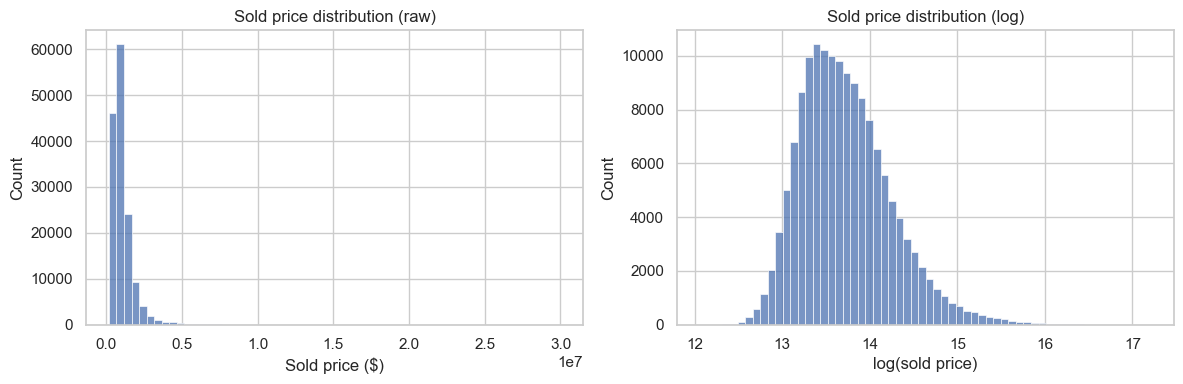

count      150000.0
mean      1073917.0
std        812530.0
min        172600.0
1%         356700.0
5%         442700.0
25%        623700.0
50%        856650.0
75%       1239800.0
95%       2361410.0
99%       4344403.0
max      30000000.0
Name: sold_price, dtype: float64


In [ ]:
target = listings["sold_price"].dropna()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(target, bins=60, ax=axes[0])
axes[0].set_title("Sold price distribution (raw)")
axes[0].set_xlabel("Sold price ($)")
sns.histplot(np.log(target[target > 0]), bins=60, ax=axes[1])
axes[1].set_title("Sold price distribution (log)")
axes[1].set_xlabel("log(sold price)")
plt.tight_layout()
plt.show()
print(target.describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).round(0))

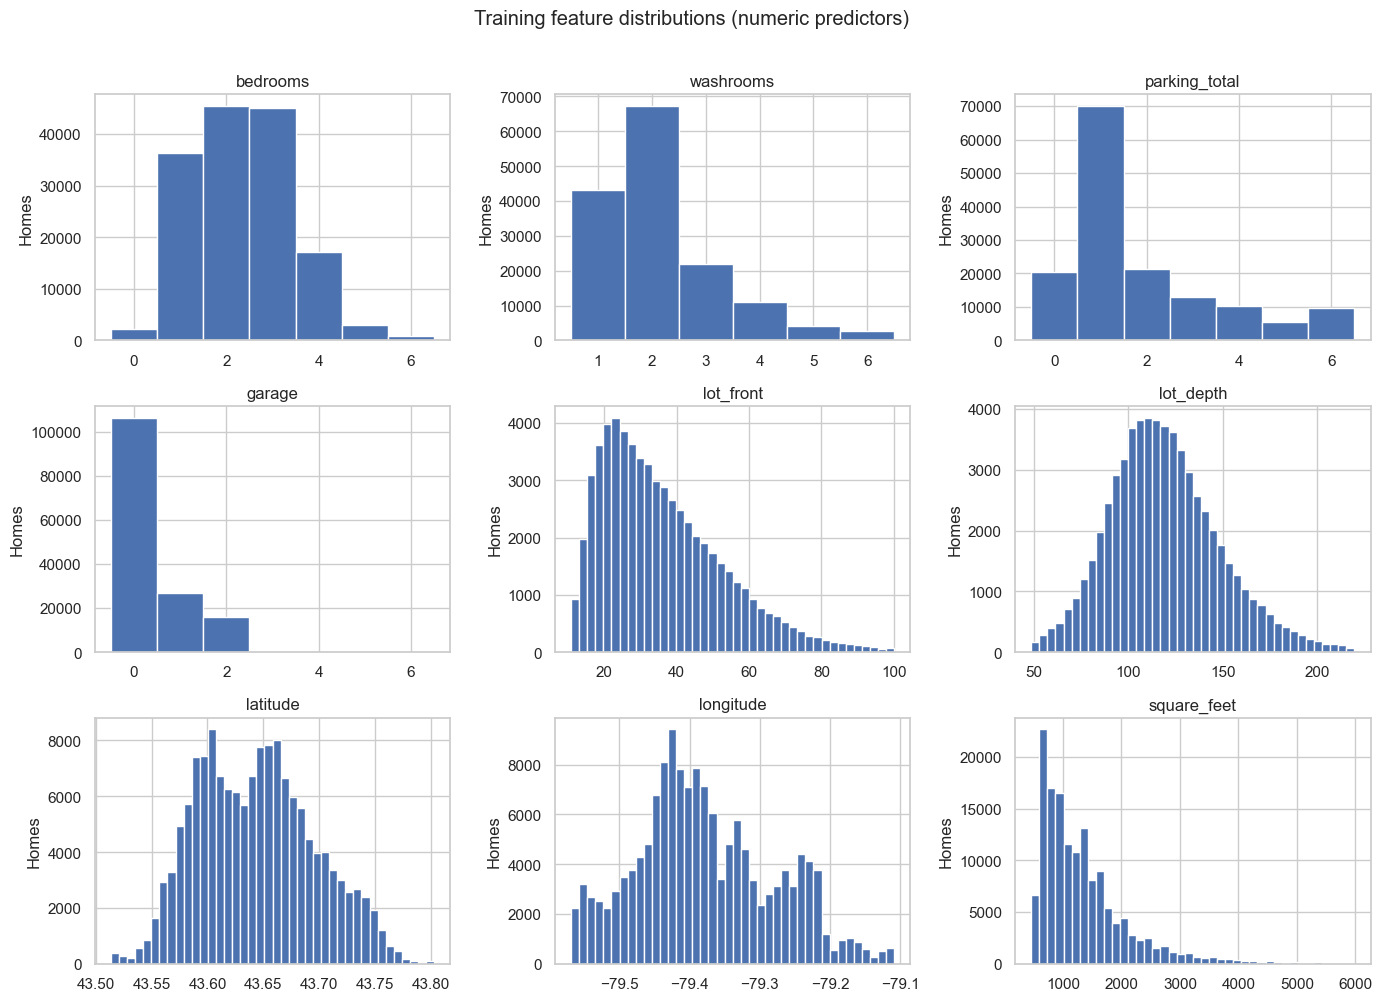

In [ ]:
COUNT_COLUMNS = {"bedrooms", "washrooms", "parking_total", "garage"}
EXCLUDE_FROM_PREDICTOR_EDA = {
    "sold_price", "list_price", "days_on_market", "external_avm_estimate",
    "external_avm_estimate_date", "ml_num"
}

numeric_cols = [c for c in listings.select_dtypes(include=np.number).columns
                if c not in EXCLUDE_FROM_PREDICTOR_EDA]
# square_feet is added after parsing and may be numeric
if "square_feet" not in numeric_cols:
    numeric_cols.append("square_feet")
numeric_cols = [c for c in numeric_cols if c in listings.columns]

ncols = 3
nrows = int(np.ceil(len(numeric_cols) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(14, 3.3 * nrows))
axes = np.atleast_1d(axes).ravel()
for ax, col in zip(axes, numeric_cols):
    values = listings[col].dropna()
    if values.empty:
        ax.set_visible(False)
        continue
    if col in COUNT_COLUMNS and values.nunique() <= 30:
        bins = np.arange(values.min() - 0.5, values.max() + 1.5, 1)
        ax.hist(values, bins=bins, edgecolor="white")
    else:
        lo, hi = values.quantile([0.005, 0.995])
        shown = values[values.between(lo, hi)]
        ax.hist(shown, bins=40, edgecolor="white")
    ax.set_title(col)
    ax.set_ylabel("Homes")
for ax in axes[len(numeric_cols):]:
    ax.set_visible(False)
fig.suptitle("Training feature distributions (numeric predictors)", y=1.01)
fig.tight_layout()
plt.show()

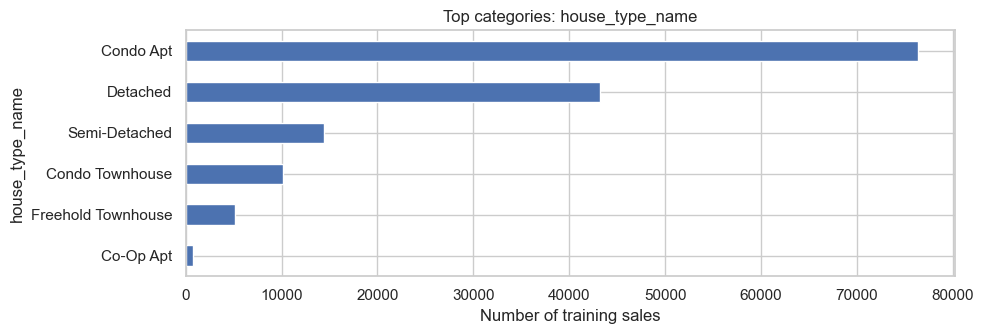

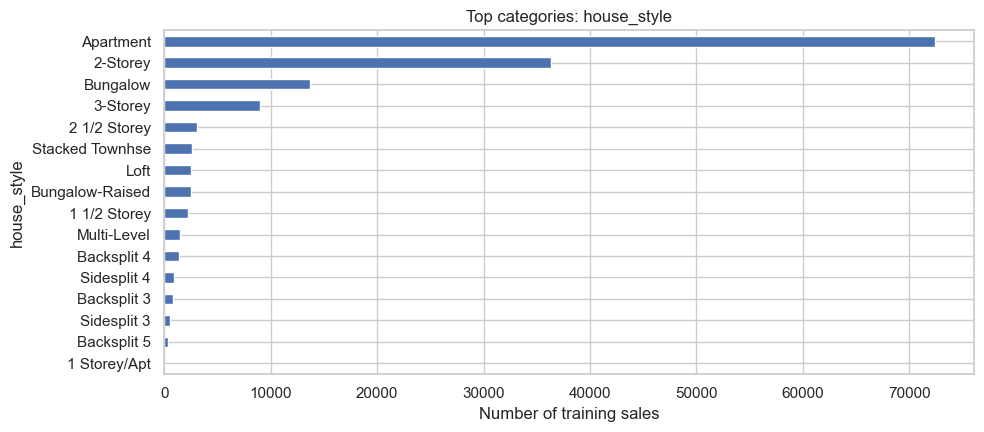

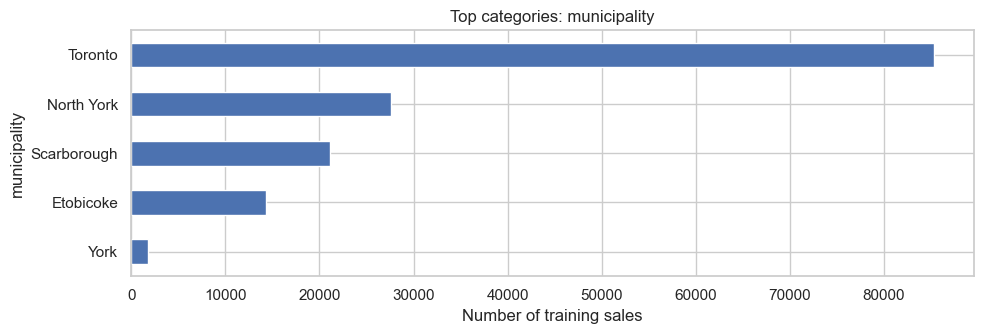

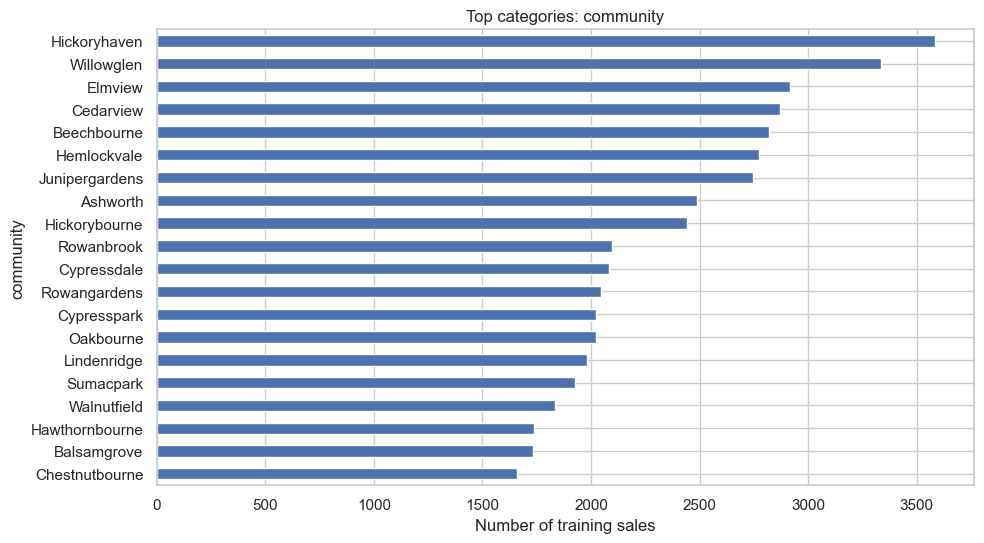

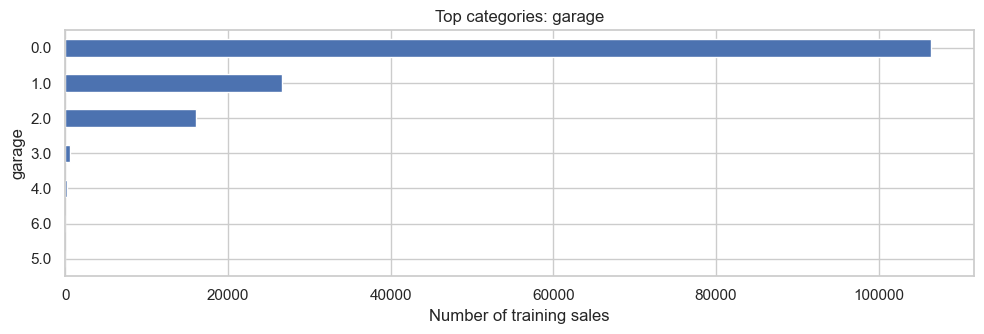

In [ ]:
categorical_candidates = [c for c in ["house_type_name", "house_style", "municipality", "community", "garage"]
                           if c in listings.columns]
for col in categorical_candidates:
    counts = listings[col].fillna("Missing").astype(str).value_counts().head(20).sort_values()
    fig, ax = plt.subplots(figsize=(10, max(3.5, 0.28 * len(counts))))
    counts.plot(kind="barh", ax=ax)
    ax.set_title(f"Top categories: {col}")
    ax.set_xlabel("Number of training sales")
    ax.set_ylabel(col)
    fig.tight_layout()
    plt.show()

,n,median,mean
house_type_name,,,
Detached,43202,1367850.0,1688778.0
Semi-Detached,14397,1179100.0,1322291.0
Freehold Townhouse,5138,1146600.0,1283139.0
Condo Townhouse,10160,786200.0,842633.0
Co-Op Apt,729,646600.0,755316.0
Condo Apt,76374,644300.0,699026.0


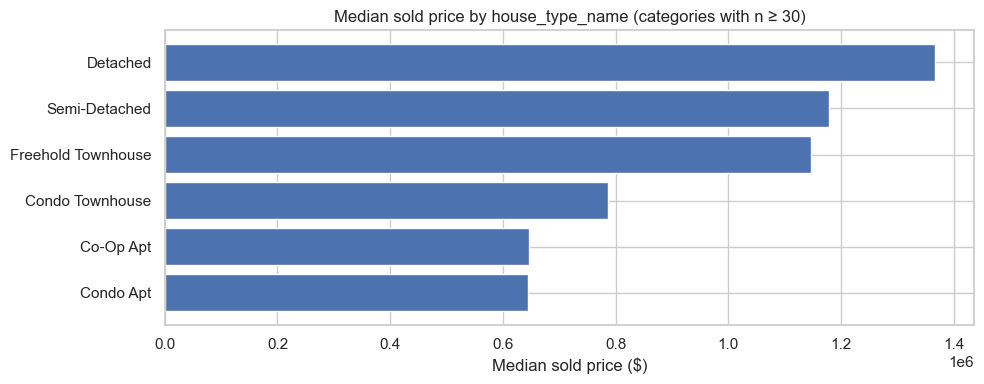

,n,median,mean
house_style,,,
2 1/2 Storey,3117,1549100.0,1960546.0
Sidesplit 3,574,1380950.0,1568352.0
Sidesplit 4,928,1342550.0,1564453.0
Backsplit 3,805,1289200.0,1488979.0
Backsplit 4,1395,1273500.0,1488842.0
2-Storey,36357,1253500.0,1519372.0
Backsplit 5,320,1252900.0,1403522.0
1 1/2 Storey,2247,1250700.0,1436348.0
3-Storey,8962,1216000.0,1635331.0


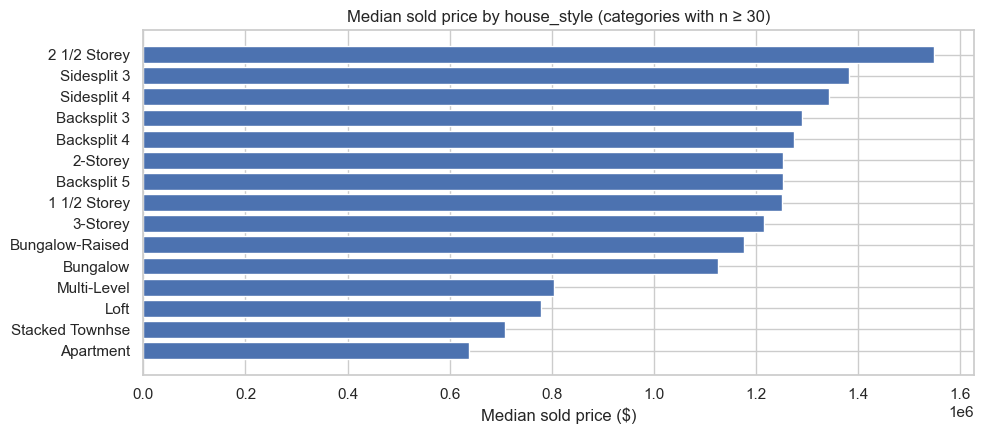

,n,median,mean
municipality,,,
Toronto,85323,894600.0,1124123.0
North York,27555,835800.0,1038979.0
Scarborough,21078,814100.0,1028169.0
York,1729,786200.0,886261.0
Etobicoke,14315,742600.0,931949.0


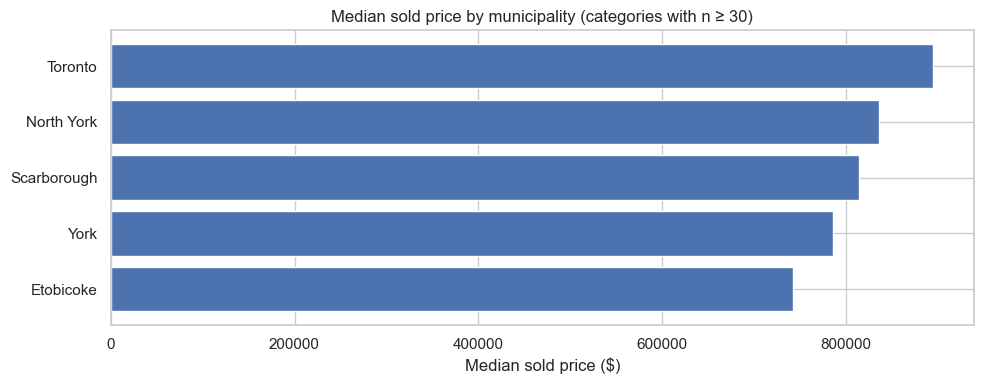

20 communities with the most training sales:


,n,median
community,,
Hickoryhaven,3584,716700.0
Willowglen,3337,767400.0
Elmview,2917,1001700.0
Cedarview,2871,544800.0
Beechbourne,2821,840800.0
Hemlockvale,2774,1327550.0
Junipergardens,2747,1190500.0
Ashworth,2487,876100.0
Hickorybourne,2442,662450.0


20 highest-median communities with at least 30 sales:


,n,median
community,,
Maplepark,408,3851550.0
Beechcrest,352,3434300.0
Hazelfield,884,2363450.0
Maplemills,477,2134000.0
Maplevale,1234,1961250.0
Poplargardens,665,1807200.0
Rowanhollow,461,1729900.0
Juniperheights,1456,1705750.0
Maplegrove,721,1578800.0


In [ ]:
for col in ["house_type_name", "house_style", "municipality"]:
    if col not in listings.columns:
        continue
    summary = (listings.groupby(col, dropna=False)["sold_price"]
               .agg(n="count", median="median", mean="mean")
               .sort_values("median", ascending=False))
    display(summary.round(0))
    plot_data = summary[summary["n"] >= 30].sort_values("median").tail(25)
    if not plot_data.empty:
        fig, ax = plt.subplots(figsize=(10, max(4, 0.3 * len(plot_data))))
        ax.barh(plot_data.index.astype(str), plot_data["median"])
        ax.set_title(f"Median sold price by {col} (categories with n ≥ 30)")
        ax.set_xlabel("Median sold price ($)")
        fig.tight_layout()
        plt.show()

if "community" in listings.columns:
    community_summary = (listings.groupby("community", dropna=False)["sold_price"]
                         .agg(n="count", median="median")
                         .query("n >= 30"))
    print("20 communities with the most training sales:")
    display(community_summary.sort_values("n", ascending=False).head(20))
    print("20 highest-median communities with at least 30 sales:")
    display(community_summary.sort_values("median", ascending=False).head(20))

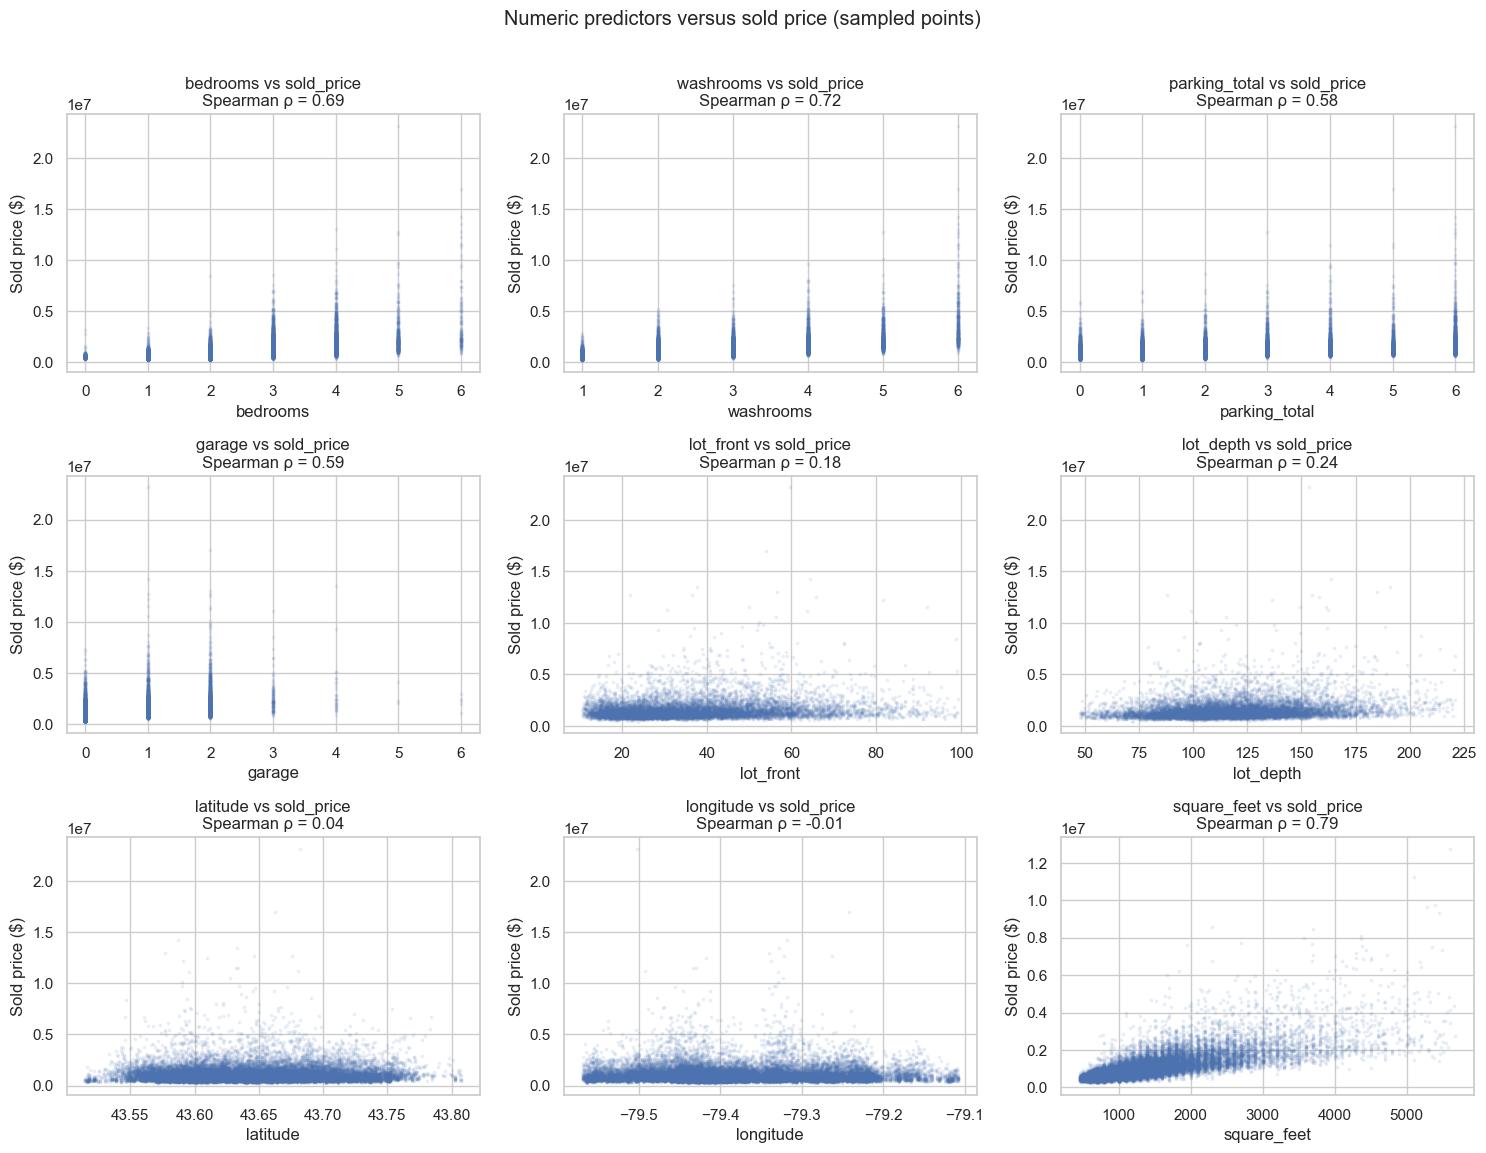

In [ ]:
from scipy.stats import spearmanr

plot_cols = [c for c in numeric_cols if c in listings.columns and listings[c].notna().sum() > 10]
rng = np.random.default_rng(RANDOM_STATE)
plot_sample = listings.sample(min(25000, len(listings)), random_state=RANDOM_STATE)
ncols = 3
nrows = int(np.ceil(len(plot_cols) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(15, 3.8 * nrows))
axes = np.atleast_1d(axes).ravel()
for ax, col in zip(axes, plot_cols):
    pair = listings[[col, "sold_price"]].dropna()
    if pair[col].nunique() < 2 or len(pair) < 3:
        ax.set_visible(False)
        continue
    rho = spearmanr(pair[col], pair["sold_price"]).statistic
    shown = plot_sample[[col, "sold_price"]].dropna()
    if col not in COUNT_COLUMNS:
        lo, hi = shown[col].quantile([0.005, 0.995])
        shown = shown[shown[col].between(lo, hi)]
    ax.scatter(shown[col], shown["sold_price"], s=7, alpha=0.12, linewidths=0)
    ax.set_title(f"{col} vs sold_price\nSpearman ρ = {rho:.2f}")
    ax.set_xlabel(col)
    ax.set_ylabel("Sold price ($)")
for ax in axes[len(plot_cols):]:
    ax.set_visible(False)
fig.suptitle("Numeric predictors versus sold price (sampled points)", y=1.01)
fig.tight_layout()
plt.show()

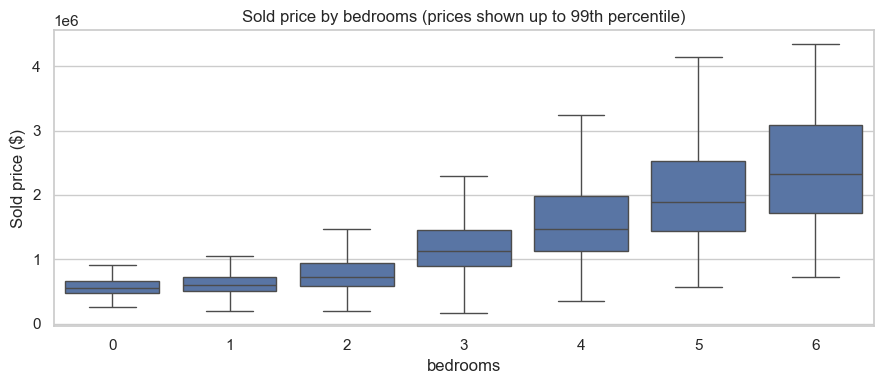

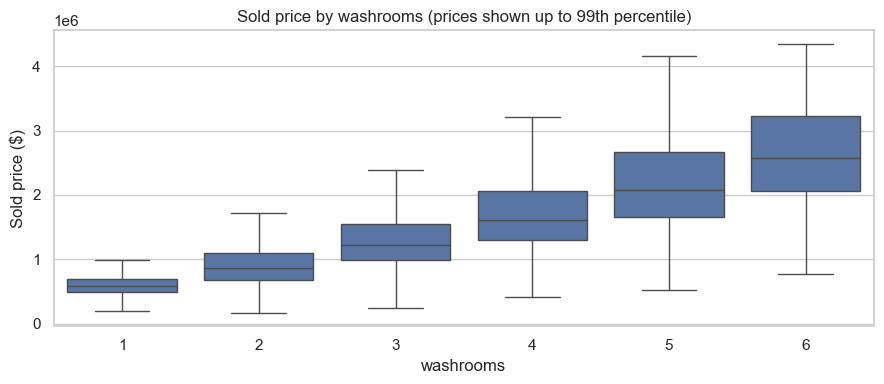

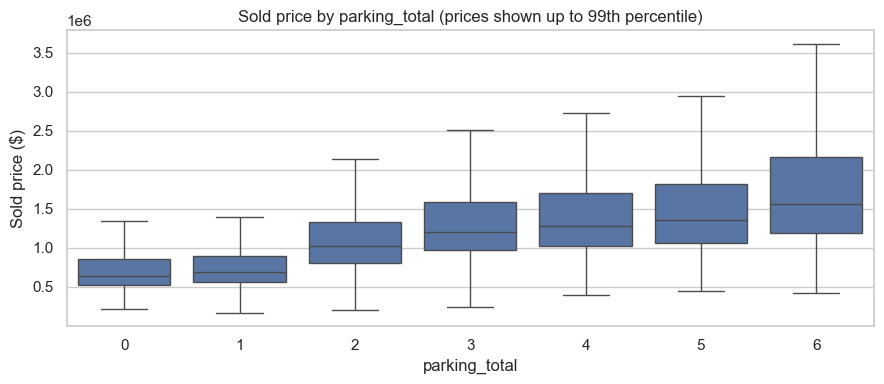

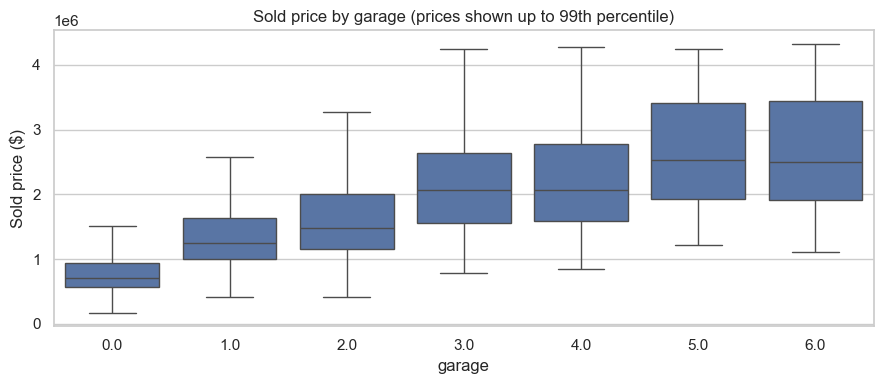

In [ ]:
price_cap = listings["sold_price"].quantile(0.99)
for col in ["bedrooms", "washrooms", "parking_total", "garage"]:
    if col not in listings.columns:
        continue
    shown = listings[listings["sold_price"] <= price_cap][[col, "sold_price"]].dropna()
    if shown[col].nunique() > 25:
        continue
    fig, ax = plt.subplots(figsize=(9, 4))
    sns.boxplot(data=shown, x=col, y="sold_price", ax=ax, showfliers=False)
    ax.set_title(f"Sold price by {col} (prices shown up to 99th percentile)")
    ax.set_xlabel(col)
    ax.set_ylabel("Sold price ($)")
    fig.tight_layout()
    plt.show()

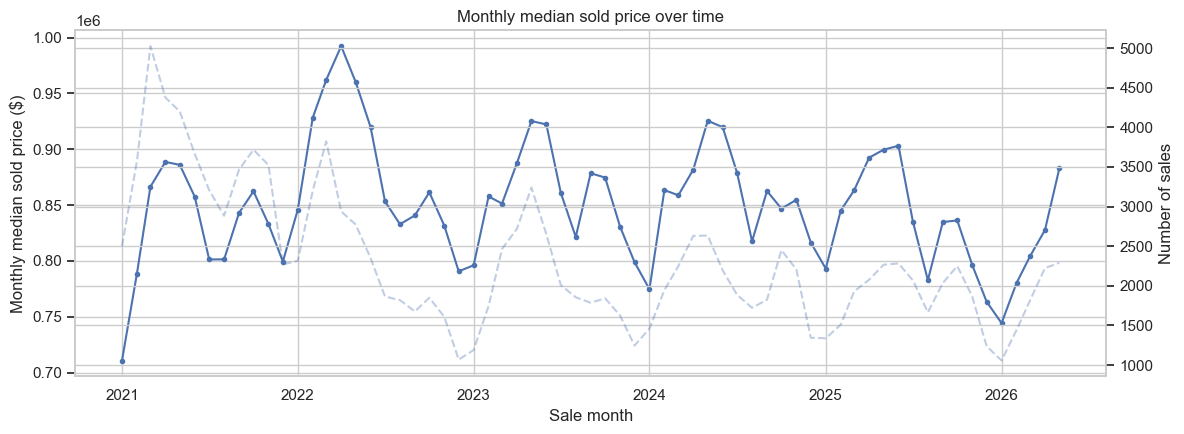

,median_sold_price,sales
sale_month,,
2025-06-01,903100.0,2283
2025-07-01,835000.0,2068
2025-08-01,782750.0,1666
2025-09-01,834800.0,2035
2025-10-01,836250.0,2250
2025-11-01,796400.0,1867
2025-12-01,763450.0,1238
2026-01-01,744300.0,1058
2026-02-01,780100.0,1442


Listing month coverage: 2020-02-01 00:00:00 to 2026-05-01 00:00:00


In [ ]:
if "date_sold" in listings.columns:
    monthly = (listings.dropna(subset=["date_sold", "sold_price"])
               .assign(sale_month=lambda d: d["date_sold"].dt.to_period("M").dt.to_timestamp())
               .groupby("sale_month")
               .agg(median_sold_price=("sold_price", "median"), sales=("sold_price", "size")))
    fig, ax1 = plt.subplots(figsize=(12, 4.5))
    ax1.plot(monthly.index, monthly["median_sold_price"], marker="o", markersize=3)
    ax1.set_ylabel("Monthly median sold price ($)")
    ax1.set_xlabel("Sale month")
    ax1.set_title("Monthly median sold price over time")
    ax2 = ax1.twinx()
    ax2.plot(monthly.index, monthly["sales"], alpha=0.35, linestyle="--")
    ax2.set_ylabel("Number of sales")
    fig.tight_layout()
    plt.show()
    display(monthly.tail(12).round(0))

if "date_listed" in listings.columns:
    listings["listing_month"] = listings["date_listed"].dt.to_period("M").dt.to_timestamp()
    print("Listing month coverage:", listings["listing_month"].min(), "to", listings["listing_month"].max())

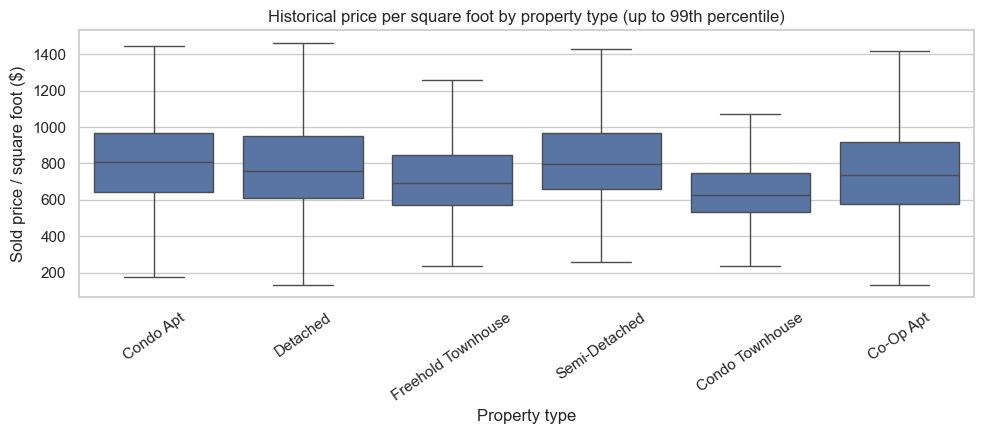

n  median_psf
house_type_name    community                       
Detached           Hawthornbourne    44      2082.4
                   Hazelfield       111      1942.4
                   Rowanhollow       20      1717.9
                   Juniperheights   234      1652.9
                   Lindendale       651      1486.3
                   Willowpark       289      1397.5
                   Sycamoreglen     219      1358.9
Co-Op Apt          Elmview           21      1356.3
Detached           Cypressdale      259      1316.7
                   Elmgardens        22      1241.7
                   Rowangrove       161      1219.2
                   Lindenglen        33      1201.4
                   Cypressbrook     390      1166.2
Semi-Detached      Magnoliacrest     82      1156.9
Detached           Elmcrest         131      1149.3
Condo Apt          Rowanhollow      111      1143.6
Detached           Maplevale       1100      1139.0
                   Poplargardens    554      1137.0
Condo Apt          Oakcrest          56      1132.9
Freehold Townhouse Hazelfield       169      1129.6
Detached           Tamarackbourne   327      1124.1
Freehold Townhouse Magnoliacrest     39      1109.5
Condo Apt          Juniperheights   310      1104.4
Semi-Detached      Juniperheights   641      1099.6
Freehold Townhouse Hawthornbourne    28      1093.5

In [ ]:
valid_psf = listings[(listings["sold_price"] > 0) & (listings["square_feet"] > 0)].copy()
valid_psf["price_per_sqft"] = valid_psf["sold_price"] / valid_psf["square_feet"]
psf_cap = valid_psf["price_per_sqft"].quantile(0.99)
fig, ax = plt.subplots(figsize=(10, 4.5))
sns.boxplot(data=valid_psf[valid_psf["price_per_sqft"] <= psf_cap],
            x="house_type_name", y="price_per_sqft", ax=ax, showfliers=False)
ax.set_title("Historical price per square foot by property type (up to 99th percentile)")
ax.set_xlabel("Property type")
ax.set_ylabel("Sold price / square foot ($)")
ax.tick_params(axis="x", rotation=35)
fig.tight_layout()
plt.show()

psf_summary = (valid_psf.groupby(["house_type_name", "community"])["price_per_sqft"]
               .agg(n="count", median_psf="median")
               .query("n >= 20")
               .sort_values("median_psf", ascending=False))
display(psf_summary.head(25).round(1))

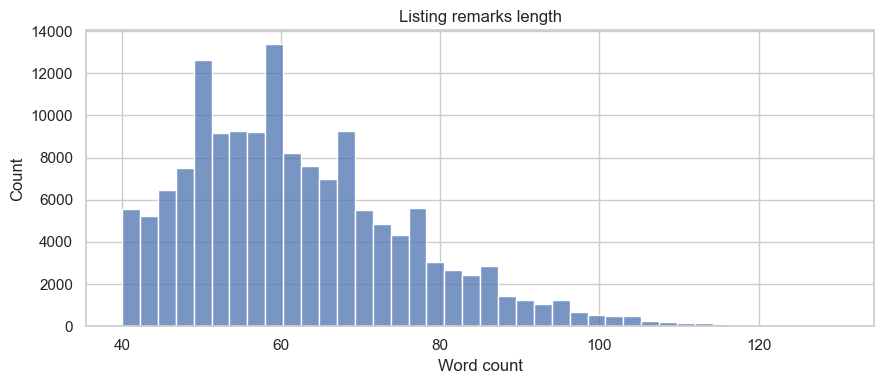

,keyword,sales_with_keyword,share_pct,median_sold_with,median_sold_without
7,parking,59153,39.0,886500.0,836000.0
2,new,43749,29.0,861200.0,854800.0
11,original,37296,25.0,811600.0,872100.0
4,garage,23782,16.0,1331650.0,778200.0
12,potential,22966,15.0,877400.0,853100.0
8,view,22238,15.0,699400.0,892600.0
14,as-is,22206,15.0,793000.0,868900.0
10,modern,22094,15.0,838500.0,860100.0
0,renovat,21165,14.0,928400.0,845500.0
13,turnkey,19925,13.0,860700.0,855900.0


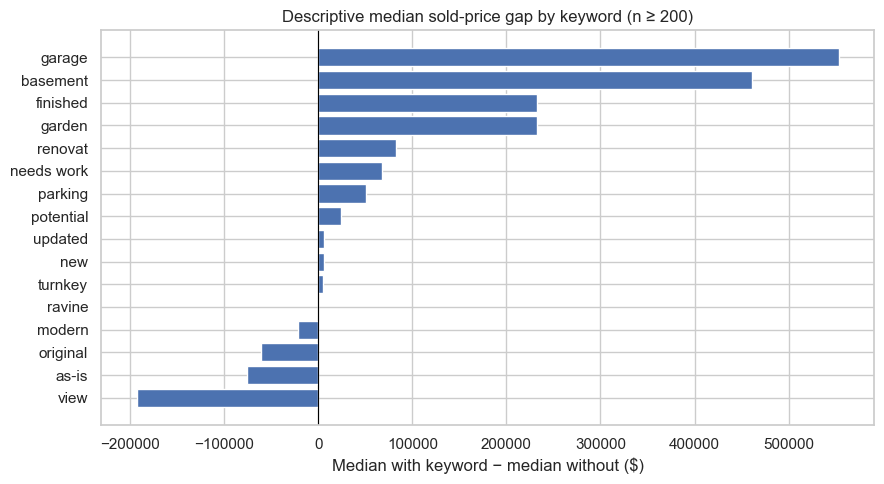

In [ ]:
if "remarks" in listings.columns:
    remarks = listings["remarks"].fillna("").astype(str)
    listings["remarks_word_count"] = remarks.str.split().str.len()
    fig, ax = plt.subplots(figsize=(9, 4))
    sns.histplot(listings["remarks_word_count"], bins=40, ax=ax)
    ax.set_title("Listing remarks length")
    ax.set_xlabel("Word count")
    plt.tight_layout()
    plt.show()

    keywords = ["renovat", "updated", "new", "finished", "garage", "needs work",
                "basement", "parking", "view", "ravine", "modern", "original",
                "potential", "turnkey", "as-is", "pool", "garden", "waterfront"]
    text_lower = listings["remarks"].fillna("").astype(str).str.lower()
    rows = []
    for kw in keywords:
        mask = text_lower.str.contains(kw, regex=False)
        rows.append({
            "keyword": kw,
            "sales_with_keyword": int(mask.sum()),
            "share_pct": round(100 * mask.mean(), 2),
            "median_sold_with": listings.loc[mask, "sold_price"].median(),
            "median_sold_without": listings.loc[~mask, "sold_price"].median(),
        })
    keyword_summary = pd.DataFrame(rows).sort_values("sales_with_keyword", ascending=False)
    display(keyword_summary.round(0))
    common = keyword_summary[keyword_summary["sales_with_keyword"] >= 200].copy()
    common["median_gap"] = common["median_sold_with"] - common["median_sold_without"]
    common = common.sort_values("median_gap")
    if len(common):
        fig, ax = plt.subplots(figsize=(9, 5))
        ax.barh(common["keyword"], common["median_gap"])
        ax.axvline(0, color="black", linewidth=0.8)
        ax.set_title("Descriptive median sold-price gap by keyword (n ≥ 200)")
        ax.set_xlabel("Median with keyword − median without ($)")
        plt.tight_layout()
        plt.show()
else:
    print("No remarks column available.")

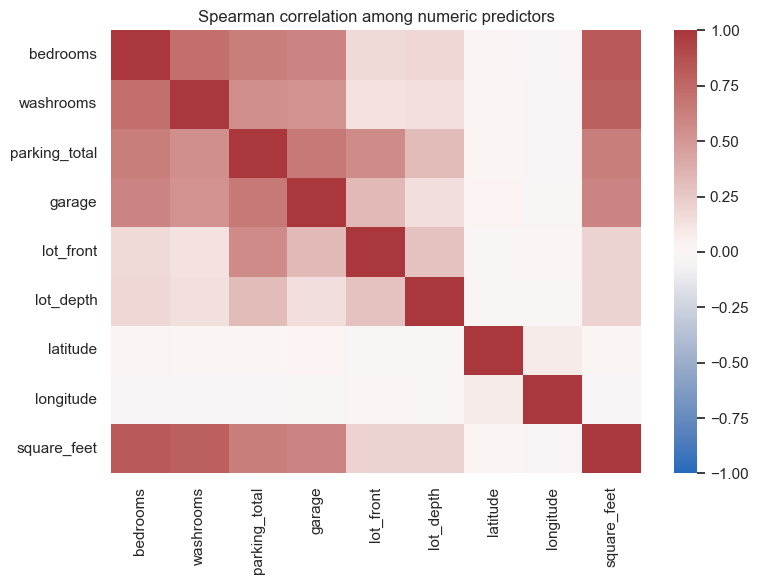

,bedrooms,washrooms,parking_total,garage,lot_front,lot_depth,latitude,longitude,square_feet
bedrooms,1.00,0.72,0.64,0.61,0.17,0.18,0.03,-0.04,0.83
washrooms,0.72,1.00,0.54,0.53,0.13,0.14,0.02,-0.03,0.79
parking_total,0.64,0.54,1.00,0.66,0.56,0.32,0.02,-0.03,0.64
garage,0.61,0.53,0.66,1.00,0.32,0.14,0.03,-0.04,0.60
lot_front,0.17,0.13,0.56,0.32,1.00,0.29,-0.02,0.01,0.20
lot_depth,0.18,0.14,0.32,0.14,0.29,1.00,-0.01,-0.01,0.20
latitude,0.03,0.02,0.02,0.03,-0.02,-0.01,1.00,0.08,0.02
longitude,-0.04,-0.03,-0.03,-0.04,0.01,-0.01,0.08,1.00,-0.04
square_feet,0.83,0.79,0.64,0.60,0.20,0.20,0.02,-0.04,1.00


In [ ]:
corr_cols = [c for c in numeric_cols if c in listings.columns and listings[c].nunique(dropna=True) > 1]
if len(corr_cols) >= 2:
    corr = listings[corr_cols].corr(method="spearman", numeric_only=True)
    fig, ax = plt.subplots(figsize=(max(8, 0.65 * len(corr_cols)), max(6, 0.55 * len(corr_cols))))
    sns.heatmap(corr, cmap="vlag", center=0, vmin=-1, vmax=1, ax=ax)
    ax.set_title("Spearman correlation among numeric predictors")
    plt.tight_layout()
    plt.show()
    display(corr.round(2))